In [1]:
# Imports

import pandas as pd
import json
import matplotlib.pyplot as plt

from matplotlib.transforms import offset_copy
from math import radians, sin, cos

In [2]:
# Load

with open("data/weather.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data["hourly"], columns=["time", "wind_speed_10m", "wind_direction_10m"])

df["time"] = pd.to_datetime(df["time"], unit="s", utc=True)
df["time"] = df["time"].dt.tz_convert("America/Edmonton")

df = df.loc[df["time"].between("2025-01-01", "2026-01-01", inclusive="left")]

df.head()

,time,wind_speed_10m,wind_direction_10m
0,2025-01-01 00:00:00-07:00,7.0,3.0
1,2025-01-01 01:00:00-07:00,6.1,5.0
2,2025-01-01 02:00:00-07:00,5.3,11.5
3,2025-01-01 02:00:00-07:00,5.3,10.0
4,2025-01-01 03:00:00-07:00,6.5,6.0


In [3]:
# Inspect

# Structure
print(df["time"].min(), "to", df["time"].max(), "\n")
print("Shape:", df.shape, "\n")
print("Dtypes:")
print(df.dtypes, "\n")

# Missingness
print("Any Nulls:", df.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", df.duplicated().any())
print("Duplicate Times:", df["time"].duplicated().any(), "\n")

# Temporal Sanity
print("Non-Monotonic Times:", not df["time"].is_monotonic_increasing)
print("Unexpected Time Deltas:", df["time"].diff().dropna().ne(pd.Timedelta(hours = 1)).any(), "\n")

# Value Sanity
display(df[["wind_speed_10m", "wind_direction_10m"]].describe().T)

2025-01-01 00:00:00-07:00 to 2025-12-31 23:00:00-07:00 

Shape: (9007, 3) 

Dtypes:
time                  datetime64[us, America/Edmonton]
wind_speed_10m                                 float64
wind_direction_10m                             float64
dtype: object 

Any Nulls: False 

Duplicate Rows: False
Duplicate Times: True 

Non-Monotonic Times: False
Unexpected Time Deltas: True 



,count,mean,std,min,25%,50%,75%,max
wind_speed_10m,9007.0,9.890885,4.780223,0.2,6.6,9.1,12.3,36.2
wind_direction_10m,9007.0,212.150161,91.980248,1.0,147.0,233.0,278.0,360.0


In [4]:
# Additional Inspect - Duplicate Times

duplicates = pd.DataFrame({"Duplicate Times": df["time"].duplicated()})

duplicate_summary = pd.DataFrame({"count": duplicates.sum(),
                                  "pct": duplicates.mean().mul(100).round(2).astype(str).add("%")
})

display(duplicate_summary)

,count,pct
Duplicate Times,247,2.74%


# Value Definitions

<div style="display: inline-block; text-align: left;">
    
| Variable / concept | Definition |
|:---|:---|
| time | Hourly observation timestamp in America/Edmonton |
| wind_speed_10m | Wind speed measured at 10 m above ground level, in km/h |
| wind_direction_10m | Direction from which the wind originates, in degrees clockwise from North |
| Direction sector | One of eight equally sized 45° compass sectors, centered on the cardinal and intercardinal directions |
| Boundary convention | Lower-inclusive, upper-exclusive; 360° equivalent to 0° |
| Mean wind speed| Arithmetic mean of eligible hourly wind speeds within each sector |

</div>

### Sector Table:

<div style="display: inline-block; text-align: left;">

| Sector | Interval |
|:---|:---|
| N | [337.5°, 360°] and [0°, 22.5°) |
| NE | [22.5°, 67.5°) |
| E | [67.5°, 112.5°) |
| SE | [112.5°, 157.5°) |
| S | [157.5°, 202.5°) |
| SW | [202.5°, 247.5°) |
| W | [247.5°, 292.5°) |
| NW | [292.5°, 337.5°) |

</div>

The inclusion of 360° in North is deliberate; it's equivalent to 0°.

In [5]:
duplicate_df = (df.loc[df["time"].duplicated(keep = False)]
                  .sort_values("time"))

print("Affected Timestamps:", duplicate_df["time"].nunique())
print("Rows Involved:", len(duplicate_df))

display(duplicate_df.head(20))

Affected Timestamps: 247
Rows Involved: 494


,time,wind_speed_10m,wind_direction_10m
2,2025-01-01 02:00:00-07:00,5.3,11.5
3,2025-01-01 02:00:00-07:00,5.3,10.0
6,2025-01-01 05:00:00-07:00,6.2,9.5
7,2025-01-01 05:00:00-07:00,6.2,8.0
29,2025-01-02 03:00:00-07:00,6.9,63.5
30,2025-01-02 03:00:00-07:00,6.9,62.0
165,2025-01-07 18:00:00-07:00,18.3,253.5
166,2025-01-07 18:00:00-07:00,18.3,252.0
272,2025-01-12 04:00:00-07:00,11.0,290.5
273,2025-01-12 04:00:00-07:00,11.0,289.0


In [6]:
# Check for missing times

expected = pd.date_range(start="2025-01-01",
                         end="2026-01-01",
                         freq="h",
                         tz="America/Edmonton",
                         inclusive="left")

actual = pd.DatetimeIndex(pd.to_datetime(df["time"], utc=True).unique())

missing = expected.difference(actual)

print("Expected hours:", len(expected))
print("Missing hours:", len(missing))

Expected hours: 8760
Missing hours: 0


In [7]:
# Check the range of duplicate times

df["time"].value_counts().loc[lambda x: x > 1].sort_index().sort_values(ascending = True)

time
2025-01-01 02:00:00-07:00    2
2025-09-15 12:00:00-06:00    2
2025-09-15 13:00:00-06:00    2
2025-09-15 14:00:00-06:00    2
2025-09-15 15:00:00-06:00    2
                            ..
2025-08-15 04:00:00-06:00    2
2025-08-15 05:00:00-06:00    2
2025-08-15 06:00:00-06:00    2
2025-08-15 08:00:00-06:00    2
2025-12-29 05:00:00-07:00    2
Name: count, Length: 247, dtype: int64

In [8]:
# Wind Directions in duplicate_df are all very close. oO they all sit in the same direction bins?

test_df = (df.loc[df["time"].duplicated(keep=False), ["time", "wind_direction_10m"]]
             .assign(n=lambda x: x.groupby("time").cumcount())
             .pivot(index="time", columns="n", values="wind_direction_10m")
             .rename(columns={0: "direction_a", 1: "direction_b"})
             .reset_index())

def direction_bin(s):
    return pd.cut(s.replace(360, 0),
                  bins = [0, 22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5, 360],
                  labels = ["N", "NE", "E", "SE", "S", "SW", "W", "NW", "N"],
                  right=False,
                  ordered=False)

test_df["bin_a"] = direction_bin(test_df["direction_a"])
test_df["bin_b"] = direction_bin(test_df["direction_b"])

test_df = test_df.assign(same = lambda x: x["bin_a"].eq(x["bin_b"]))

display(test_df.loc[test_df["same"].eq(False)])

n,time,direction_a,direction_b,bin_a,bin_b,same
42,2025-07-31 09:00:00-06:00,157.5,156.0,S,SE,False
58,2025-08-13 23:00:00-06:00,337.5,336.0,N,NW,False
105,2025-08-15 22:00:00-06:00,202.5,201.0,SW,S,False
142,2025-09-14 22:00:00-06:00,292.5,291.0,NW,W,False
201,2025-09-28 01:00:00-06:00,338.5,337.0,N,NW,False
223,2025-09-28 23:00:00-06:00,157.5,156.0,S,SE,False


In [9]:
# Confirm No Duplicate Wind Speeds

print("No Duplicate Wind Speeds:", duplicate_df.groupby("time")["wind_speed_10m"].nunique().eq(1).all())

No Duplicate Wind Speeds: True


In [10]:
# Clean - Remove all timestamps where the duplicate direction isn't the same

delete = test_df.loc[~test_df["same"], "time"]

clean_df = (df.loc[~df["time"].isin(delete)]
              .drop_duplicates(subset="time", keep="first")
              .copy())

display(clean_df)
print("Duplicate Times:", clean_df["time"].duplicated().sum())

,time,wind_speed_10m,wind_direction_10m
0,2025-01-01 00:00:00-07:00,7.0,3.0
1,2025-01-01 01:00:00-07:00,6.1,5.0
2,2025-01-01 02:00:00-07:00,5.3,11.5
4,2025-01-01 03:00:00-07:00,6.5,6.0
5,2025-01-01 04:00:00-07:00,6.4,10.0
...,...,...,...
9002,2025-12-31 19:00:00-07:00,13.4,301.0
9003,2025-12-31 20:00:00-07:00,11.9,299.0
9004,2025-12-31 21:00:00-07:00,10.9,294.0
9005,2025-12-31 22:00:00-07:00,9.0,292.0


Duplicate Times: 0


In [11]:
# Transform

sector_order = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]

output_df = (clean_df.assign(sector = lambda x: direction_bin(x["wind_direction_10m"]))
                     .groupby("sector", as_index = False, observed = True)
                     .agg(avg_wind_speed = ("wind_speed_10m", "mean"),
                          count = ("sector", "size"))
                     .set_index("sector")
                     .reindex(sector_order)
                     .reset_index())

display(output_df)

,sector,avg_wind_speed,count
0,N,11.300923,975
1,NE,7.347826,483
2,E,6.886051,509
3,SE,9.679633,1198
4,S,8.866017,1077
5,SW,9.718790,1256
6,W,10.939773,2205
7,NW,10.319791,1051


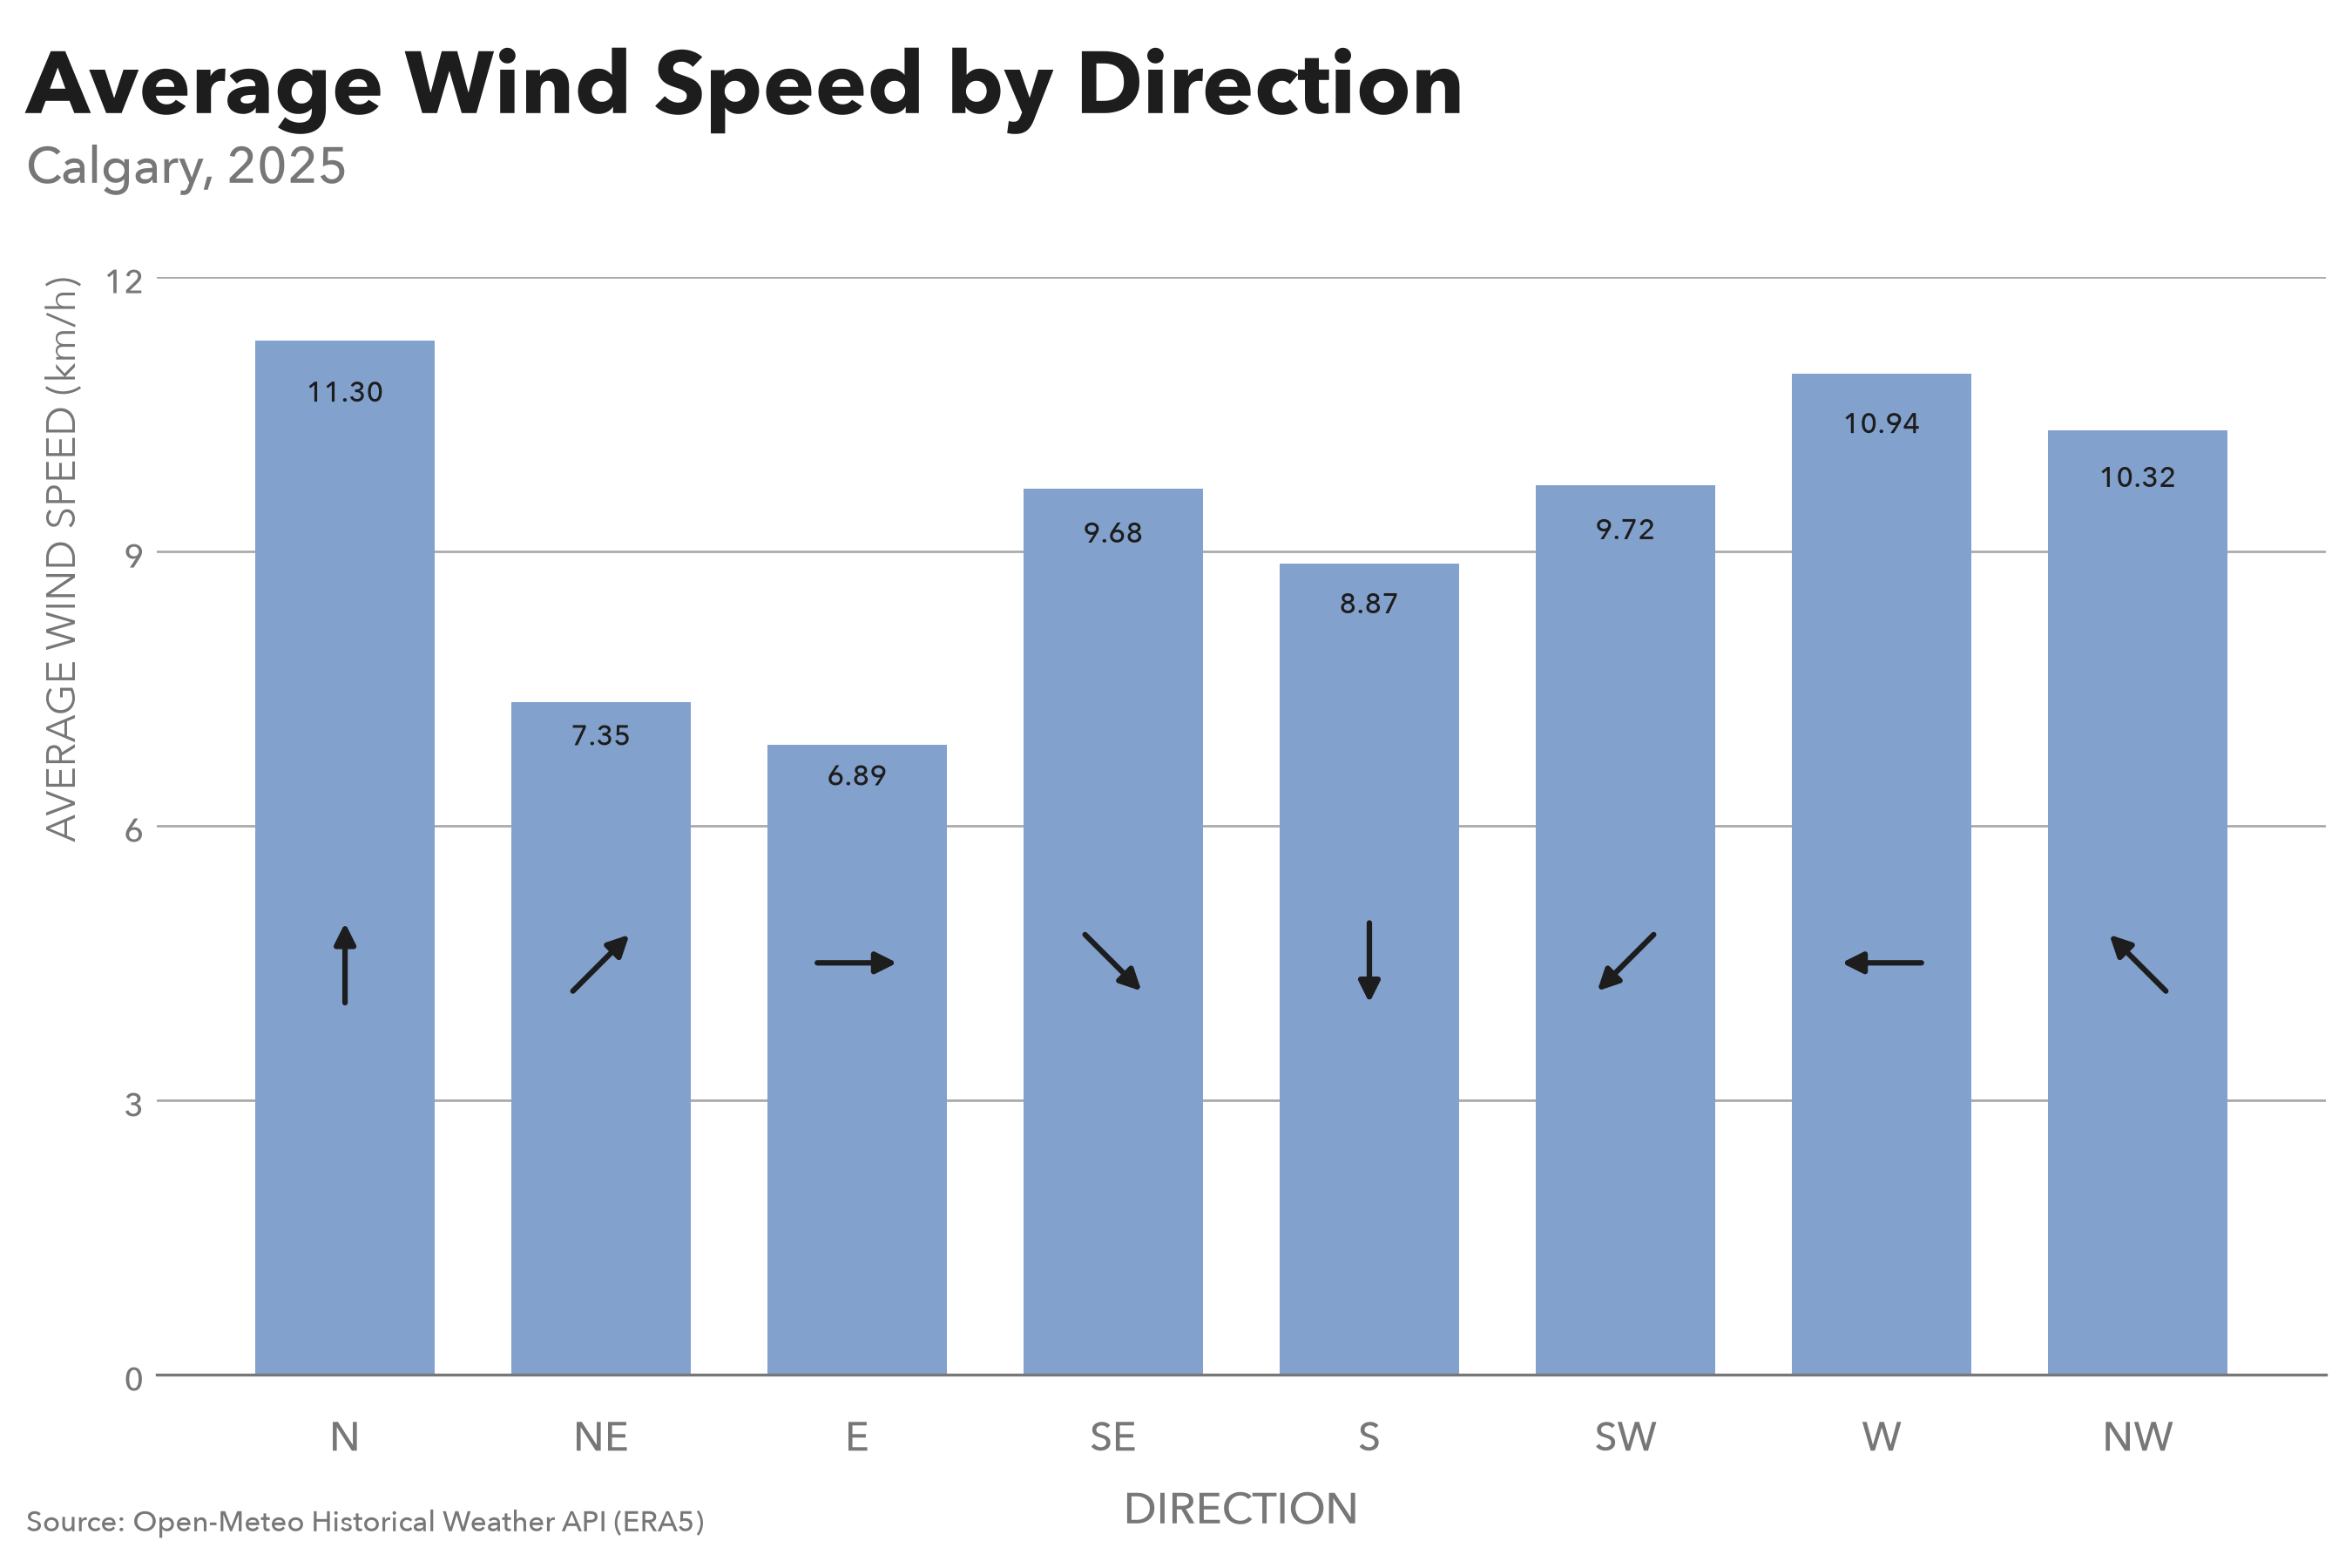

In [12]:
# Visualize

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 500

fig, ax = plt.subplots(figsize = (10, 6), dpi = 300)

fig.subplots_adjust(
    left = 0.10,
    right = 0.93,
    top = 0.80,
    bottom = 0.10
)

STRUCTURE = "#777777"
GRID = "#A9A9A9"
BLUE = "#83A1CD"
BLACK = "#1D1D1D"

# Plot

bars = ax.bar(output_df["sector"], output_df["avg_wind_speed"], width = 0.70, color = BLUE, linewidth = 0)

for bar, avg in zip(bars, output_df["avg_wind_speed"]):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() * 0.95,
            f"{avg:.2f}",
            ha="center", va="center",
            fontsize=8, fontweight=500, color=BLACK)

# Emphasis

#arrow directions
def direction_arrow(ax, x, y, angle, length=22):
    angle = radians(angle)

    dx = length * sin(angle)
    dy = length * cos(angle)

    tip_coords = offset_copy(ax.transData,
                             fig = ax.figure,
                             x = dx / 2,
                             y = dy / 2,
                             units = "points"
    )

    ax.annotate("",
                xy = (x, y),
                xycoords = tip_coords,
                xytext = (-dx, -dy),
                textcoords = "offset points",
                arrowprops = dict(arrowstyle = "-|>",
                                  color = BLACK,
                                  lw = 1.5,
                                  mutation_scale = 12,
                                  shrinkA = 0,
                                  shrinkB = 0
                )
    )

direction_angles = {"N": 0,
                    "NE": 45,
                    "E": 90,
                    "SE": 135,
                    "S": 180,
                    "SW": 225,
                    "W": 270,
                    "NW": 315}

for bar, sector in zip(bars, output_df["sector"]):
    x = bar.get_x() + bar.get_width() / 2

    direction_arrow(ax,
                    x = x,
                    y = 4.5,
                    angle = direction_angles[sector],
                    length = 22
    )

# Scale & Axes

ax.set_ylim(0, 12)

ax.set_ylabel("AVERAGE WIND SPEED (km/h)", loc = "top", fontsize = 11, color = STRUCTURE)

ax.set_xlabel("DIRECTION", loc = "center", fontsize = 12, fontweight = 500, color = STRUCTURE)

# Ticks

ax.set_yticks([0, 3, 6, 9, 12])

ax.tick_params(axis = "x", labelsize = 11, length = 0, pad = 10, labelcolor = STRUCTURE)
ax.tick_params(axis = "y", labelsize = 9, length = 0, labelcolor = STRUCTURE)

# Styling

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(STRUCTURE)

ax.set_axisbelow(True)
ax.grid(axis = "y", color = GRID, linewidth = 0.65)

# Composition

fig.suptitle("Average Wind Speed by Direction", x = 0.05, y = 0.96, ha = "left", va = "top", fontweight = 700, fontsize = 24, color = BLACK)

fig.text(0.05, 0.86, "Calgary, 2025", fontsize = 14, color = STRUCTURE)

fig.text(0.05, 0, "Source: Open-Meteo Historical Weather API (ERA5)", fontsize = 8, fontweight = 500, color = STRUCTURE)

# Output

fig.savefig("outputs/avg_wind_speed_by_direction_2025.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()